# Phase 23 — Literature & Methodological Novelty Audit

### A systematic prior-art audit of a **provisional** candidate contribution, conducted BEFORE architecture freeze or any implementation

| Item | Value |
|---|---|
| Phase | 23 — Literature & Methodological Novelty Audit |
| Canonical folder | `notebooks/phasewise/phase_23_literature_novelty/` |
| Purpose | Try to **disprove** the novelty of the provisional candidate before committing to a design |
| Predecessor | `PHASE22_CANONICAL_IPYNB_MATERIALIZED__VISUAL_INTEGRITY_PASS__SCIENCE_UNCHANGED__PHASE23_ELIGIBLE_NOT_STARTED` |
| Search date | 2026-09-29 |
| New training | **NONE** (0 optimizers, 0 backward passes, 0 checkpoint writes) |
| Segmentation inference | **NONE** |
| Cohort read | **NONE** (no TRAIN/VAL/TEST pixels are read; only persisted audit/tables) |
| TEST | **CLOSED** — 0 image reads, 0 mask reads, 0 inference, 0 visualizations |
| Overall novelty label | `PARTIALLY_OCCUPIED__NARROWER_NOVELTY_POSSIBLE` |
| Max defensible claim level | **Level 2**, scoped to the unoccupied combination (Level 3 **not** defensible) |
| Phase 24 | **ELIGIBLE, NOT STARTED** (narrowed spec only) |
| Terminal state | `PHASE23_NOVELTY_AUDIT_COMPLETE__PARTIALLY_OCCUPIED__PHASE24_NARROWED_SPEC_ELIGIBLE_NOT_STARTED` |

**What Phase 23 is.** A *literature and methodological novelty audit*: it searches prior art
systematically, inspects the closest works deeply, and determines what — if anything —
remains defensible about the candidate contribution. It exists to protect the project from
building on a claim that a reviewer could refute with one citation.

**What Phase 23 is NOT.** It is **NOT** an implementation, **NOT** an architecture
specification (that is Phase 24, and only a *narrowed* one), **NOT** a training phase, and it
does **NOT** reinterpret any Phase-22 result. No experiment was run. TEST is never touched.

## 2. Entry gate (fail-closed)

Before any audit work, every predecessor identity and governance lock is verified. If any
check fails the gate writes `PHASE23_ENTRY_GATE_FAIL` and exits non-zero. The gate never
repairs frozen science.

In [1]:
import json, hashlib, pathlib
import pandas as pd

ROOT = pathlib.Path(r"D:/Softfors/jup")
AUD = ROOT / "reports" / "audits"
TAB = ROOT / "reports" / "tables"

from IPython.display import Image, Markdown, display

def _j(p):
    p = pathlib.Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else {}

def sty(df, uid, fmt=None):
    """Deterministic pandas Styler (fixed uuid so builds are byte-identical)."""
    s = df.style
    if fmt:
        s = s.format(fmt)
    return s.set_uuid(uid)

FIG = ROOT / "reports" / "figures" / "phase23_novelty_audit"

def fig(name, caption=None):
    """Embed a Phase-23 figure as a REAL inline image output.

    FAIL-CLOSED: raises if the figure is missing, empty, or not a valid PNG.
    Phase 23 figures are built by scripts/analysis/build_phase23_visuals.py from
    frozen tables/audits only; no search is performed from notebook execution.
    """
    p = FIG / name
    if not p.exists():
        raise FileNotFoundError(f"FAIL-CLOSED: required Phase-23 figure missing: {p}")
    raw = p.read_bytes()
    if not raw.startswith(b"\x89PNG\r\n\x1a\n"):
        raise ValueError(f"FAIL-CLOSED: not a PNG: {p}")
    if len(raw) < 2048:
        raise ValueError(f"FAIL-CLOSED: suspiciously small PNG ({len(raw)}B): {p}")
    _img = Image(data=raw, format="png", embed=True)
    return display(_img) if caption is None else display(Markdown(f"**{caption}**"), _img)

gate = _j(AUD / "phase23_entry_gate.json")
print("entry gate verdict :", gate.get("verdict"))
print("checks             :", f"{gate.get('n_passed')}/{gate.get('n_checks')}")
print("no training        :", gate.get("no_training"))
print("no segmentation inf:", gate.get("no_segmentation_inference"))
print("TEST reads         :", gate.get("test_reads"))
print("phase24 started    :", gate.get("phase24_started"))

df_gate = pd.DataFrame(gate.get("checks", []))[["check", "pass", "detail"]]
df_gate

entry gate verdict : PHASE23_ENTRY_GATE_PASS
checks             : 21/21
no training        : True
no segmentation inf: True
TEST reads         : 0
phase24 started    : False


,check,pass,detail
0,phase22_freeze_exists,True,reports\audits\phase22_final_freeze.json
1,phase22_freeze_sha_unchanged,True,9a0aa2f8c1a2850770fb09f2838e95f0fe08b3b40e55ab...
2,phase22_protocol_sha_unchanged,True,9d620d6c85276e1a9a086ec60172cdef3b94dc58fe8288...
3,phase21_best_checkpoint_sha_unchanged,True,286689fdd5c63ad75a383151d267af8b476e7a98327632...
4,protocol_id,True,phase22_diagnostic_protocol_v1
5,combined_audit_all_passed,True,74/74
6,predecessor_terminal_present,True,PHASE22_CANONICAL_IPYNB_MATERIALIZED__VISUAL_I...
7,phase23_not_already_started,True,False
8,phase21_macro_dice_unchanged,True,0.8350794169575282
9,test_reads_zero,True,"{""test_image_reads"": 0, ""test_mask_reads"": 0, ..."


## 3. Phase-22 motivation (used ONLY as motivation)

Phase 22 is the empirical reason this audit exists. Its facts motivate the candidate but are
**not** reinterpreted here, and no new experiment is run. The binding guards are:

- the **oracle** regional arm uses ground truth — it is an **upper bound**, not deployable;
- where a paired CI overlaps zero the arms are **not separable**;
- "lightest of the panel" ≠ "fit for constrained deployment";
- only *"achieved X vs Y"* is allowed; **"X caused +Y" is forbidden**.

The four facts that motivate the audit:
1. **Always-on regional refinement HURTS in aggregate** (mean Δ Dice −0.0425; harm 536/808).
2. **Benefit is strongly heterogeneous** (Gini 0.644; top-10% share of benefit 49.24%).
3. An **oracle selective acceptance gives a positive ceiling** (+0.0210 over always-global).
4. **Simple GT-free proxies are weak** (best |ρ| = 0.0689, ROC-AUC ≈ 0.5) — so a *learned*
   predictor would be needed, which is exactly what motivates the candidate.

In [2]:
mot = {
    "oracle_regional_mean_delta_dice": -0.04247786113739191,
    "harm_cases": "536/808",
    "oracle_ceiling_gain_over_always_global": 0.021034244277644776,
    "best_gt_free_spearman_abs": 0.068947494425616,
    "best_gt_free_roc_auc": 0.4187710871522123,
    "kub_tiny_mean_delta_dice": 0.013196596116120203,
    "kub_tiny_ci_includes_zero": True,
}
for k, v in mot.items():
    print(f"  {k:42s} {v}")

# binding: these values are read back from the frozen Phase-22 science attestation
att = _j(AUD / "phase22_reviewer_notebook_visual_repair.json").get("science_unchanged_attestation", {})
assert abs(float(att.get("oracle_regional_mean_delta")) - mot["oracle_regional_mean_delta_dice"]) < 1e-12
assert att.get("harm_cases") == mot["harm_cases"]
assert abs(float(att.get("oracle_ceiling_gain")) - mot["oracle_ceiling_gain_over_always_global"]) < 1e-12
print("\nPhase-22 motivation values match the frozen science attestation: OK")

  oracle_regional_mean_delta_dice            -0.04247786113739191
  harm_cases                                 536/808
  oracle_ceiling_gain_over_always_global     0.021034244277644776
  best_gt_free_spearman_abs                  0.068947494425616
  best_gt_free_roc_auc                       0.4187710871522123
  kub_tiny_mean_delta_dice                   0.013196596116120203
  kub_tiny_ci_includes_zero                  True

Phase-22 motivation values match the frozen science attestation: OK


## 4. The novelty hypothesis under test

The provisional candidate ("Counterfactual Benefit-Certified Refinement") decomposes into
seven testable factors. Each is audited separately; a factor that is occupied cannot carry
novelty on its own.

| # | Factor |
|---|---|
| 1 | a frozen/global pathway produces an initial result |
| 2 | an **optional** refinement/intervention exists |
| 3 | **before** executing it, the system predicts its expected improvement |
| 4 | the target is the **paired** quantity `DeltaQ = Q(refined, GT) − Q(global, GT)` |
| 5 | the prediction gates **execute vs skip** |
| 6 | a **harmful** refined output can be rejected, preserving the global prediction |
| 7 | routing may include compute/device/resource cost in shared multi-domain segmentation |

**The question is NOT "has uncertainty-guided refinement existed?"** — it almost certainly
has. The question is whether the **expected paired benefit of an optional intervention** has
been **learned before executing it** and used for **performance-preserving, resource-aware
routing**.

## 5. Search protocol

Thirteen query families were run: A–J (per the brief), plus **K falsification-first**,
**L general-CV precedence**, and **M patent scan**. K and L were purpose-built to
**disprove** the claim and were run *after* the affirmative families, so a close equivalent
would surface rather than be hidden. Every query is logged in `phase23_search_log.json`.

**Verification policy.** Every retained paper was verified against at least one primary or
authoritative index record. Items that could not be verified were **excluded** rather than
cited (`phase23_excluded_nearby_works.csv`).

**Honest limitation.** Semantic Scholar / Crossref API, ScienceDirect, and IEEE **full text**
were not reachable in-session. The log records this.

In [3]:
log = _j(AUD / "phase23_search_log.json")
print("search date        :", log.get("search_date"))
print("families           :", len(log.get("search_families", [])))
print("queries logged     :", log.get("totals", {}).get("queries_logged"))
print("results screened   :", log.get("totals", {}).get("results_screened"))
print("papers retained    :", log.get("totals", {}).get("papers_retained_authoritative"))
print("promoted to closest:", log.get("totals", {}).get("papers_promoted_to_closest_review"))
print("TEST reads         :", log.get("test_reads"))
print("training jobs      :", log.get("training_jobs_started"))

search date        : 2026-09-29
families           : 13
queries logged     : 63
results screened   : 401
papers retained    : 80
promoted to closest: 16
TEST reads         : 0
training jobs      : 0


## 6. Search-query inventory

Per-family screening and retention, with the highest-risk find in each family. This table
prevents cherry-picking: every family's yield is visible.

In [4]:
q = pd.read_csv(TAB / "phase23_search_query_summary.csv")
print("families:", len(q), "| total screened:", int(q["results_screened"].sum()),
      "| total retained:", int(q["papers_retained"].sum()))
sty(q, "p23_searchq")

families: 13 | total screened: 401 | total retained: 80


,family,label,n_queries,results_screened,papers_retained,highest_risk_found,highest_risk_level
0,A,multi-domain / universal medical segmentation,4,34,6,butoi2023universeg; ma2024medsam,MEDIUM
1,B,regional / coarse-to-fine refinement,4,31,7,isensee2021nnunet (always-run cascade),MEDIUM
2,C,uncertainty-guided refinement,4,28,5,uhrnet2026 (current-uncertainty only),MEDIUM
3,D,quality / error prediction,4,26,5,laves2018qualitypred; borges2024sdc,MEDIUM
4,E,counterfactual benefit / value-of-computation,5,40,9,russell1991metareasoning; kunzel2019metalearners,HIGH
5,F,conditional computation,5,33,6,graves2016act; wang2018skipnet,MEDIUM
6,G,mixture-of-experts / routing,4,29,6,jiang2024m4oe,HIGH
7,H,performance-preserving / safe routing,5,30,7,sanisoglu2026abstain; tan2026cls,MEDIUM
8,I,resource-aware / device-aware,5,27,5,zhang2023mobilesam,LOW
9,J,tiny-object / small-lesion,5,25,5,chou2024tinylessurvey; bouzid2023scaleaware,MEDIUM


### 6.1 Search coverage

Coverage across the 13 query families. **This is a search-coverage visualisation, not a
novelty score** — bar length reports screening effort and yield, nothing else. The right-hand
chips report the highest novelty risk *found* in each family, which is why families K and L
(the purpose-built falsification families) matter more than their record counts suggest.

**Figure 1 — search coverage: records screened and retained per query family (13 families, 63 logged queries, 401 records screened, 80 retained).**

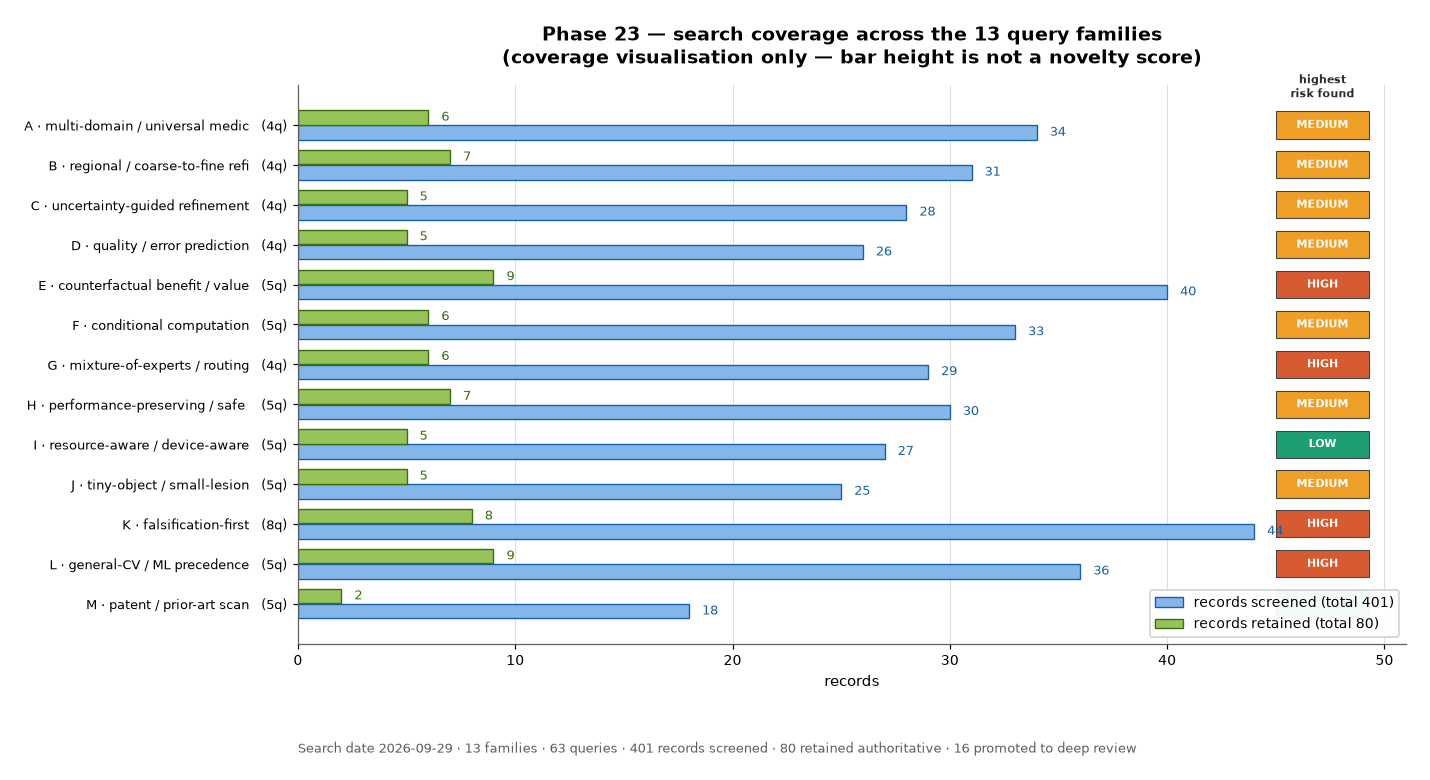

In [5]:
fig("p23_search_coverage.png",
    "Figure 1 — search coverage: records screened and retained per query family "
    "(13 families, 63 logged queries, 401 records screened, 80 retained).")

## 7. Literature taxonomy

`phase23_prior_art_matrix.csv` records every retained work against the full column set
(multi-domain, MoE/routing, refinement, uncertainty, quality/error prediction,
**predicts_future_action_benefit**, **predicts_before_action**, **paired_gain_target**,
execute/skip, fallback, resource/device terms, tiny-object, and a novelty risk). The
distribution below shows how crowded each neighbourhood is.

In [6]:
m = pd.read_csv(TAB / "phase23_prior_art_matrix.csv")
print("rows:", len(m), "| columns:", len(m.columns))
print()
print("novelty risk distribution:")
print(m["novelty_risk"].value_counts().to_string())
print()
print("HIGH-risk works:")
print(m.loc[m["novelty_risk"] == "HIGH", "citation_key"].to_string(index=False))

rows: 30 | columns: 47

novelty risk distribution:
novelty_risk
MEDIUM    15
HIGH      11
LOW        4

HIGH-risk works:
 russell1991metareasoning
      latotzke2021cascade
         viola2001cascade
   kunzel2019metalearners
        mozannar2020defer
              moon2024jfs
       shen2024meddanetv2
         shen2022meddanet
zhang2024adaptivepatching
            jiang2024m4oe
             zhao2026lfpc


### 7.1 Concept taxonomy

Eight neighbouring concepts occupy this neighbourhood. The audit's load-bearing distinctions
are that **uncertainty ≠ action benefit**, **quality prediction ≠ refinement gain**, and
**post-hoc selection ≠ pre-execution routing**. The narrowed candidate sits at
concept 5 ∩ 7 ∩ 8 with a preservation-fallback — nothing wider is claimed.

**Figure 2 — concept taxonomy: the eight neighbouring concepts, the rejected equivalences, and the narrowed candidate contribution.**

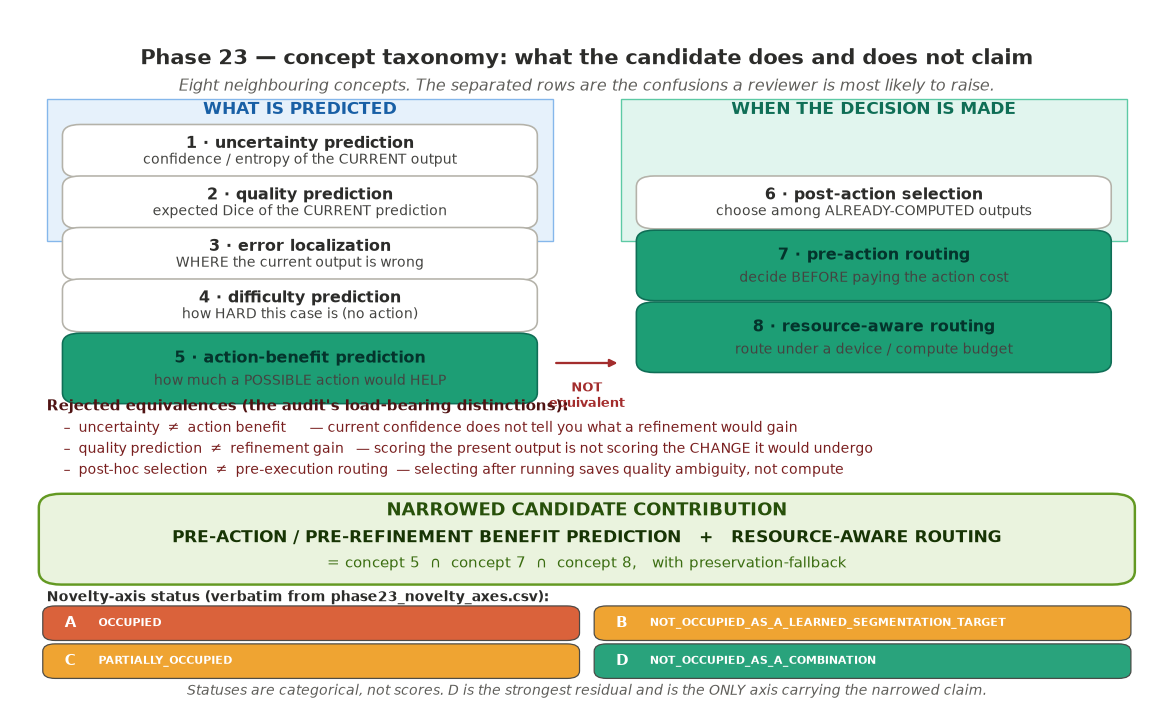

In [7]:
fig("p23_concept_taxonomy.png",
    "Figure 2 — concept taxonomy: the eight neighbouring concepts, the rejected "
    "equivalences, and the narrowed candidate contribution.")

In [8]:
# mechanism-presence census across the retained corpus
flags = [
    "predicts_future_action_benefit", "predicts_before_action",
    "paired_global_refined_gain_target", "execute_skip_gate",
    "post_refinement_accept_reject", "global_fallback",
    "resource_aware", "shared_multidomain_model", "MoE",
]
census = m[flags].apply(lambda s: (s.astype(str).str.upper() == "TRUE").sum()).to_frame("n_TRUE")
census["n_total"] = len(m)
census["fraction"] = (census["n_TRUE"] / len(m)).round(3)
print("Corpus census (how many of the 30 retained works carry each mechanism):")
print(census.to_string())

# the candidate's distinctive COMBINATION
combo = ((m["predicts_before_action"].astype(str).str.upper() == "TRUE") &
         (m["paired_global_refined_gain_target"].astype(str).str.upper() == "TRUE") &
         (m["execute_skip_gate"].astype(str).str.upper() == "TRUE"))
print(f"\nworks with before-action + paired-gain-target + execute/skip gate: {int(combo.sum())}/{len(m)}")
if int(combo.sum()):
    print(m.loc[combo, ["citation_key", "year", "medical_or_general_cv", "novelty_risk"]].to_string(index=False))

Corpus census (how many of the 30 retained works carry each mechanism):
                                   n_TRUE  n_total  fraction
predicts_future_action_benefit          4       30     0.133
predicts_before_action                 11       30     0.367
paired_global_refined_gain_target       3       30     0.100
execute_skip_gate                      12       30     0.400
post_refinement_accept_reject           2       30     0.067
global_fallback                         7       30     0.233
resource_aware                         13       30     0.433
shared_multidomain_model                4       30     0.133
MoE                                     4       30     0.133

works with before-action + paired-gain-target + execute/skip gate: 1/30
     citation_key  year medical_or_general_cv novelty_risk
mozannar2020defer  2020            general_ml         HIGH


### 7.2 Prior-art mechanism coverage

Each precedent **family** (row) against the mechanism **properties** the candidate relies on
(column). A filled cell means at least one retained work in that family carries that primitive.

The reading is deliberately deflationary: **individual primitives are widely occupied**, and the
candidate survives only as the integration in the bottom row. Absence from this matrix is
**absence from the audited scope only** — it does not prove worldwide uniqueness.

**Figure 3 — prior-art mechanism coverage by precedent family. Filled = at least one retained work carries the primitive; bottom row = the candidate's integration.**

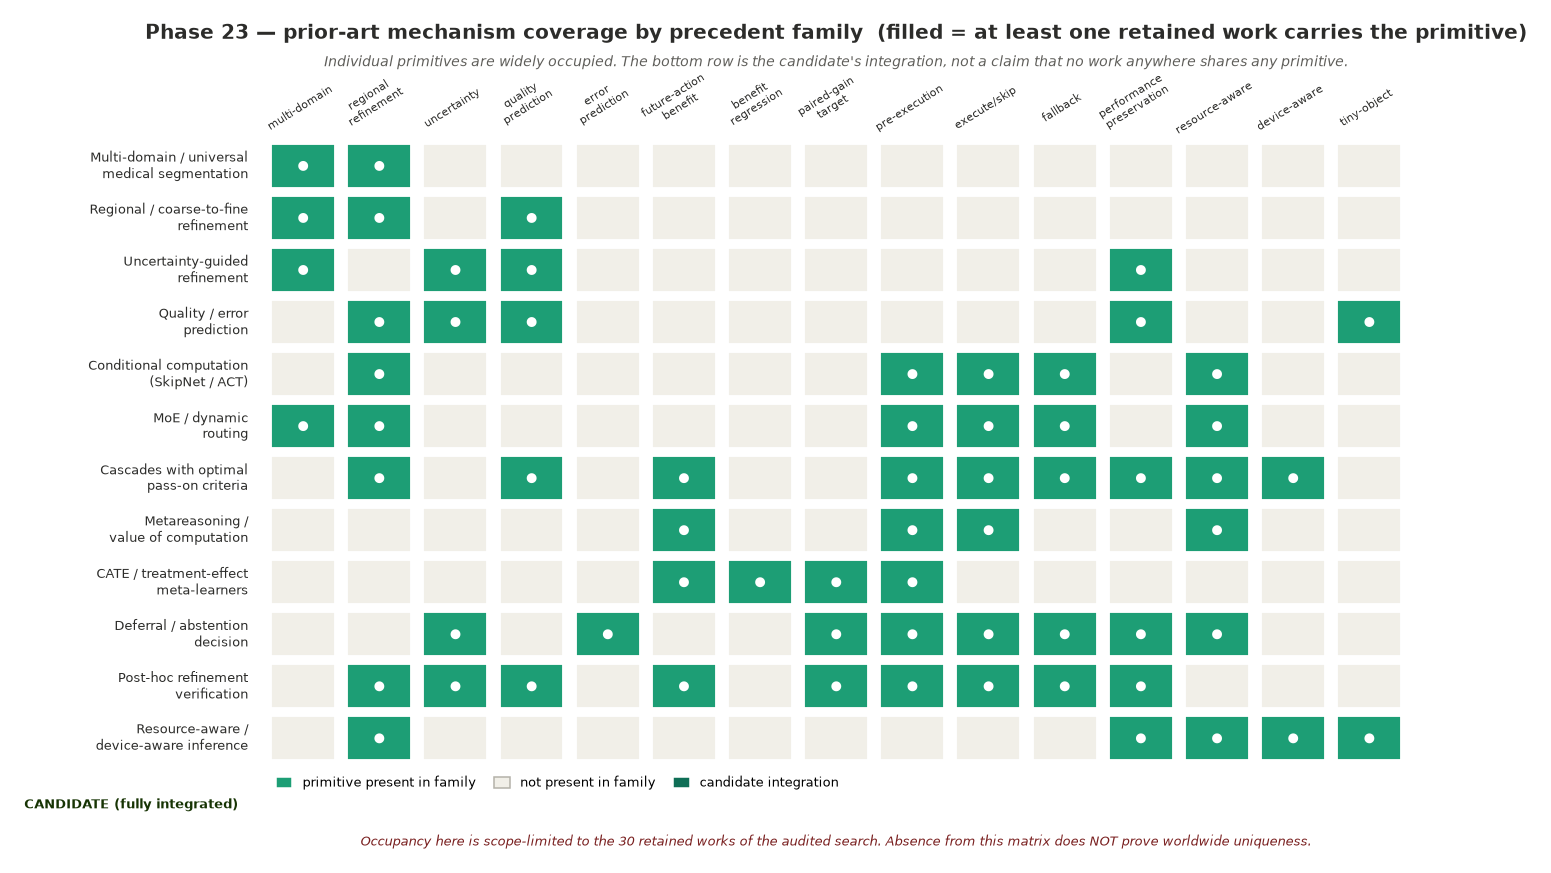

In [9]:
fig("p23_prior_art_mechanism_matrix.png",
    "Figure 3 — prior-art mechanism coverage by precedent family. Filled = at least one "
    "retained work carries the primitive; bottom row = the candidate's integration.")

## 8. Multi-domain / universal medical segmentation — **OCCUPIED**

A single frozen model spanning many medical domains is established: **UniverSeg** (ICCV
2023, 53 datasets), **MedSAM** (Nature Comms 2024, 11 modalities), **SAM-Med2D**,
**MedUniSeg**, **M4oE** (MICCAI 2024). These remove "shared multi-domain medical segmentor"
from any novelty claim.

## 9. Refinement prior art — **OCCUPIED (as a primitive)**

Refinement itself is not novel: **SegRefiner** (NeurIPS 2023), **nnU-Net**'s always-run 3D
cascade (Nature Methods 2021), scale-aware super-resolution for lesions. The important point
is that these refinement passes are **unconditional** — they are the expensive step a gate
would decide *on*, not a competing gate.

## 10. Uncertainty-guided refinement — **OCCUPIED, and driven by CURRENT uncertainty**

Uncertainty-guided refinement exists (UHR-Net and family, DEviS). But it overwhelmingly uses
**current** uncertainty to decide *where* to refine, not a prediction of the **benefit** of
the refinement. The critical distinction (§7 of the brief) is uncertainty ≠ benefit-of-action.

## 11. Quality / error prediction — **OCCUPIED, but targets CURRENT quality**

**Laves et al. (MICCAI 2018)**, **Soft Dice Confidence** (Borges et al. 2024), **EvanySeg**
(2024) all predict segmentation quality **without ground truth** — that is solved. Crucially
they estimate the quality of the **current** mask, never `refined − global`. This is the
boundary that separates the two problem statements.

## 12. Conditional computation — **OCCUPIED**

**ACT** (Graves 2016), **SkipNet** (ECCV 2018), **Mixture-of-Depths** (2024), **Adaptive
Computation Modules**. Learned execute/skip of computation with a cost penalty is a mature
field. Gating is common; a regression on a paired GT-derived `DeltaQ` for a segmentation
refinement is not.

## 13. MoE / dynamic routing — **OCCUPIED (medical, multi-domain)**

**M4oE** routes modality-specific experts with a learned gate; **DeferredSeg** (2026) does
pixel-wise predict-then-route over a second pathway (a human expert). Routing selects a
**pathway/expert**, not *whether to spend on an optional refinement*. This constrains our
routing novelty to the **decision target**, not the routing mechanism.

## 14. Resource-aware inference — **OCCUPIED as ENGINEERING, not algorithmic novelty**

Lightweight/mobile/edge segmentation is a crowded domain (**MobileSAM**, edge-adaptive
networks). On its own it is **engineering value**. It becomes a defensible contribution
**only** as an explicit term in the decision utility (Phase-24 constraint C6).

## 15. Counterfactual / value-of-computation literature — **THE HARDEST THREAT**

This is the family that most limits the claim, and it must be stated plainly:

- **Metareasoning** (Russell & Wefald, *Artificial Intelligence* 1991) formalises
  **value of computation** = expected benefit of a computation **minus its cost**, decided
  **before** the computation. Our pre-refinement gate is an instance of this.
- **Cascaded classifiers** (Latotzke et al., LOD 2021; Viola–Jones, 2001) derive optimal
  **execute/skip pass-on criteria** before the expensive stage, with a cost term.
- **CATE meta-learners** (Künzel et al., *PNAS* 2019) estimate `E[Y(1) − Y(0) | x]` — the
  **identical formal target** to our `DeltaQ`, outside imaging.
- **Adaptive Inference** (Hor et al. 2024) gives theoretical bounds on
  **performance-preserving** efficiency gains.

**Conclusion:** the mechanism *"predict the benefit of a future computation, then
execute/skip"* and the paired-gain *learning target* are both **fully precedented**. No
algorithmic novelty can be claimed for either.

## 16. Closest prior works

Sixteen works are deep-compared in `phase23_closest_prior_work.csv` against the candidate on:
what it predicts, **when** it predicts it, what supervision it uses, whether refinement
already ran, whether cost is included, whether a fallback exists, and whether it is
multi-domain / medical / tiny-object / device-aware. **No arbitrary "winner" is declared** —
this is similarity analysis only.

In [10]:
c = pd.read_csv(TAB / "phase23_closest_prior_work.csv")
show = ["proximity_rank", "citation_key", "year",
        "refinement_already_ran", "action_cost_included", "fallback_exists",
        "medical", "multi_domain", "novelty_risk"]
print(f"closest works: {len(c)}")
c[show].sort_values("proximity_rank").to_string(index=False)

closest works: 16


" proximity_rank              citation_key  year                                                                   refinement_already_ran                       action_cost_included                                    fallback_exists                     medical                multi_domain novelty_risk\n              1               moon2024jfs  2024                                  YES — refinement runs first; JFS only judges the result                                         NO  YES (revert to the coarse mask on judged failure) NO (PASCAL, natural images)                          NO         HIGH\n              2        shen2024meddanetv2  2024                                                NO — the decision precedes the model call YES (efficiency is the explicit objective)                                                 NO                         YES                  NO (BraTS)         HIGH\n              3  russell1991metareasoning  1991                                                 

## 17. Exact mechanism comparison

The critical technical distinction (brief §7) is **when** the decision is made:

- If the expensive branch runs **first** and the output is chosen afterwards, **no compute is
  saved** — it is a *post-hoc verifier*.
- If benefit is estimated **before** the expensive branch, compute is saved — it is a
  *pre-execution gate*.

**JFS** (Moon et al., ICIP 2025) is the closest functional analogue in segmentation: same
problem framing, a paired coarse-vs-refined comparison, and revert-on-failure. **But JFS is
post-hoc** — it decides *after* refinement, so it saves no compute, and it is untrained.

In [11]:
cmp = c.set_index("citation_key")[[
    "when_it_predicts", "refinement_already_ran", "action_cost_included",
    "fallback_exists", "multi_domain", "medical", "tiny_object", "deployment_device_aware",
]]
# show the top-6 closest by rank in the notebook body
top = c.sort_values("proximity_rank").head(6)
for _, r in top.iterrows():
    print(f"[{int(r['proximity_rank'])}] {r['citation_key']} ({r['year']})")
    print(f"     when predicts : {r['when_it_predicts']}")
    print(f"     refinement ran: {r['refinement_already_ran']}")
    print(f"     cost included : {r['action_cost_included']}")
    print(f"     fallback      : {r['fallback_exists']}")
    print(f"     residual gap  : {r['residual_difference_from_our_candidate']}")
    print()

[1] moon2024jfs (2024)
     when predicts : AFTER refinement has already been executed (post-hoc verifier)
     refinement ran: YES — refinement runs first; JFS only judges the result
     cost included : NO
     fallback      : YES (revert to the coarse mask on judged failure)
     residual gap  : PRE-EXECUTION prediction (compute saving) + a LEARNED regression on DeltaQ = Q(refined,GT) - Q(global,GT) + cost-aware routing

[2] shen2024meddanetv2 (2024)
     when predicts : BEFORE running the segmentation model for that slice
     refinement ran: NO — the decision precedes the model call
     cost included : YES (efficiency is the explicit objective)
     fallback      : NO
     residual gap  : the decision target: expected Dice GAIN of an optional refinement (paired, GT-derived) rather than a region/quantization policy; plus preservation-fallback and multi-domain

[3] russell1991metareasoning (1991)
     when predicts : BEFORE performing the computation (definitional)
     refinement 

### 17.1 Closest works — categorical mechanism comparison

The six closest works by proximity rank, each resolved to explicit flags read from the frozen
closest-work table. **This is a property comparison, not a ranking and not a winner chart** —
in particular, the empty `paired gain is a supervised target` column across all six works is
itself the residual the audit identifies.

**Figure 4 — closest prior works: categorical mechanism comparison (proximity_rank order; property flags only).**

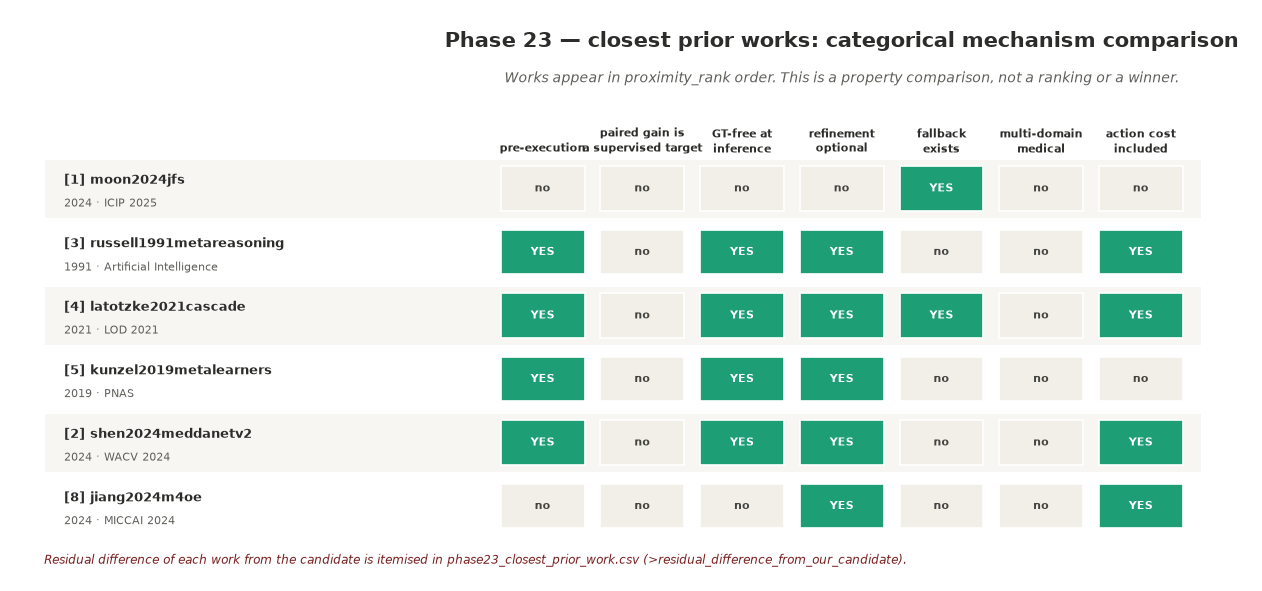

In [12]:
fig("p23_closest_prior_work_matrix.png",
    "Figure 4 — closest prior works: categorical mechanism comparison "
    "(proximity_rank order; property flags only).")

## 18. Novelty-axis matrix

Novelty is evaluated on four axes separately (brief §11). A contribution cannot claim an
axis that is occupied. Statuses are **categorical evidence**, never combined into a numeric
novelty score.

In [13]:
ax = pd.read_csv(TAB / "phase23_novelty_axes.csv")
for _, r in ax.iterrows():
    print(f"AXIS {r['axis']} — {r['axis_name']}: {r['status']}  (confidence {r['confidence']})")
    print(f"   Q: {r['question']}")
    print(f"   residual: {r['defensible_residual']}")
    print()

AXIS A — PROBLEM FORMULATION: OCCUPIED  (confidence HIGH)
   Q: Is the problem 'predict whether an optional refinement will improve the current segmentation' already explicitly formulated?
   residual: NONE at the level of problem FORMULATION — the question is explicitly asked and answered in segmentation before our work

AXIS B — LEARNING TARGET: NOT_OCCUPIED_AS_A_LEARNED_SEGMENTATION_TARGET  (confidence MEDIUM)
   Q: Has anyone explicitly trained a predictor on DeltaQ = refined outcome quality - global outcome quality for segmentation?
   residual: A SUPERVISED regression on the paired, GT-derived DeltaQ of a SEGMENTATION REFINEMENT, trained at the image level with a GT-free input space. The formal target is not novel; the instantiation is.

AXIS C — DECISION MECHANISM: PARTIALLY_OCCUPIED  (confidence MEDIUM)
   Q: Has that predicted DeltaQ been used to decide execute/skip BEFORE expensive refinement?
   residual: The COMBINATION: a gate whose decision variable is a LEARNED paired-ga

### 18.1 Novelty-axis matrix (figure)

The four axes with their exact statuses. **No axis is weighted, summed, or ranked** — axis D
carries the narrowed claim precisely because it is a combination claim, not because it "scores"
higher.

**Figure 5 — novelty-axis matrix: four categorical axes with their exact statuses, strongest prior art, and defensible residual.**

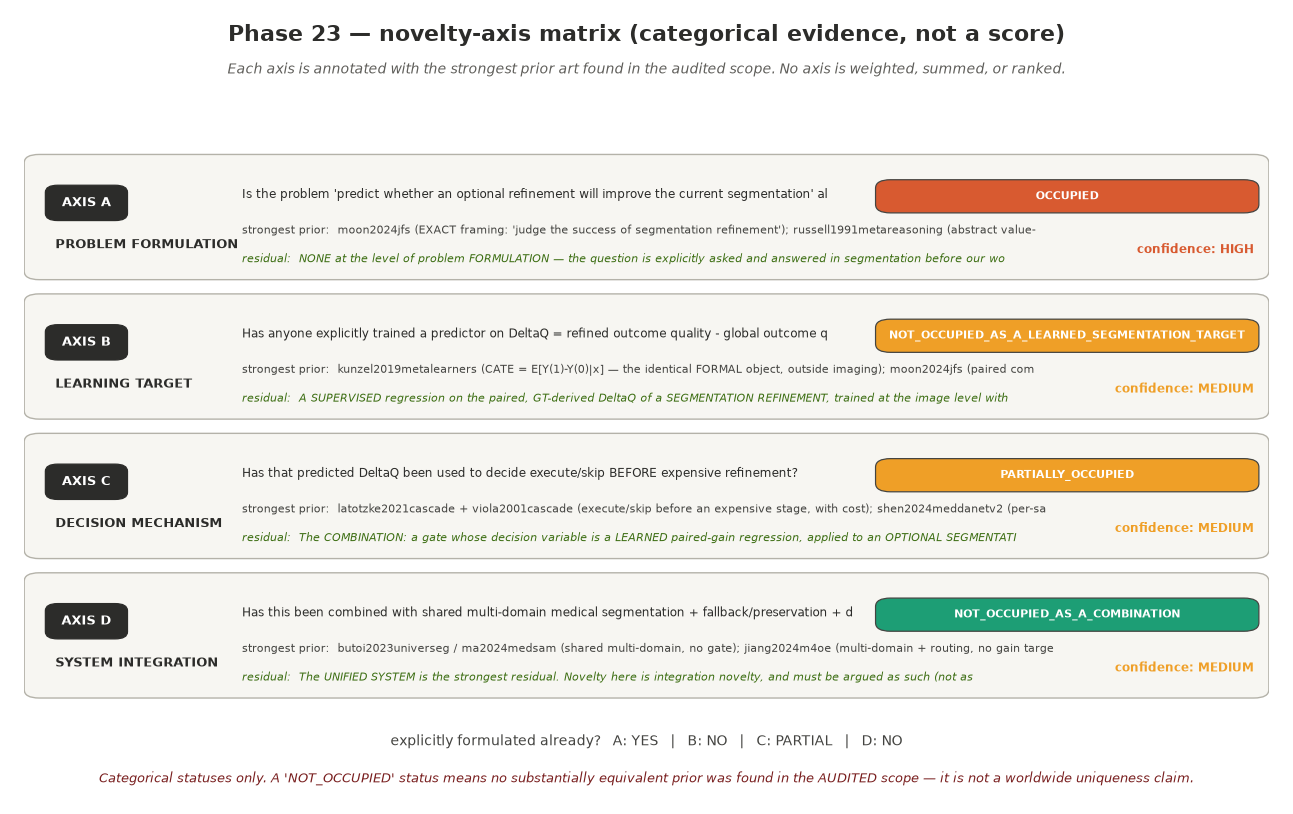

In [14]:
fig("p23_novelty_axes_matrix.png",
    "Figure 5 — novelty-axis matrix: four categorical axes with their exact statuses, "
    "strongest prior art, and defensible residual.")

## 19. Counterfactual terminology audit

**Outcome: `PREFER_PAIRED_REFINEMENT_GAIN`.**

Both potential outcomes are **fully observed** for every development image (the system can
simply run the refinement during development), so there is **no missing-data problem and no
identification strategy is needed** — the feature that makes an estimand "causal" is absent.
The refinement is also **deterministic** given `(x, frozen model, frozen ROI rule)`, so the
"effect" is a deterministic paired contrast, not a stochastic individual treatment effect.

**"Counterfactual" and "treatment effect" are therefore misleading here.** Use *paired
refinement gain*. A single caveated sentence may note the formal analogy to CATE, while
stating that the estimand is a deterministic paired contrast.

In [15]:
cf = _j(AUD / "phase23_counterfactual_terminology_audit.json")
print("outcome :", cf.get("outcome"))
print()
for qa in cf.get("questions", []):
    print("Q:", qa["question"])
    print("A:", qa["answer"][:180], "...")
    print()
print("disallowed:", "; ".join(cf.get("disallowed_wording", [])))

outcome : PREFER_PAIRED_REFINEMENT_GAIN

Q: Are both potential outcomes observed during development?
A: YES, but only JOINTLY, not as a true counterfactual. For each development image the system can compute BOTH Q(global) and Q(refined) because it may simply run the refinement during ...

Q: Is this simply supervised paired outcome prediction?
A: YES. It is a supervised regression on an observed paired difference. It is exactly a T-learner-style estimate of a paired contrast where both arms are always observed. ...

Q: Is causal identification actually needed?
A: NO. Causal identification machinery (ignorability, overlap, propensity weighting, IV) exists to handle a MISSING potential outcome. Here both outcomes are measured for every develo ...

Q: Would 'counterfactual refinement benefit' be technically defensible?
A: WEAKLY / MISLEADING. The refinement is deterministic given (x, frozen model, frozen ROI rule). The 'effect' is therefore a deterministic function of the inputs and the f

## 20. Certification terminology audit

**Outcome: `USE_BENEFIT_AWARE_ONLY`.**

"Certified" implies a **guarantee**. None is available:

| Guarantee family | Required evidence | Status |
|---|---|---|
| conformal guarantee | exchangeability + calibration set | **NOT EARNED** (the ROI/refinement rules break naive exchangeability) |
| empirical risk control | a held-out, never-inspected population + pre-declared risk | **NOT EARNED** (Phase-22 policies were post-hoc, optimistically biased) |
| calibrated confidence bound | demonstrated calibration coverage | **NOT YET EARNED** (Phase-22 GT-free proxies are near-chance) |
| simple probability threshold | a fixed threshold | achievable, **but not a certificate** |

**Recommendation:** drop "certified"; use **"benefit-aware"** (or "gain-gated"). An upgrade
path exists if a conformal/risk-control construction is later validated on held-out data —
a Phase-24+ decision, **not** authorized here.

In [16]:
ct = _j(AUD / "phase23_certification_terminology_audit.json")
print("outcome        :", ct.get("outcome"))
print("recommendation :", ct.get("recommendation"))
print()
for t in ct.get("candidate_terms_examined", []):
    print(f"  {t['term']:55s} -> {t['status']}")
print()
print("detail:", ct.get("recommendation_detail"))

outcome        : USE_CALIBRATED_IF_AND_ONLY_IF_CALIBRATION_IS_DEMONSTRATED_ELSE_USE_BENEFIT_AWARE_ONLY
recommendation : USE_BENEFIT_AWARE_ONLY

  calibrated confidence bound on predicted gain (A)       -> NOT_YET_EARNED
  conformal guarantee (B)                                 -> NOT_EARNED
  empirical risk threshold (C)                            -> NOT_EARNED
  simple probability threshold (D)                        -> ACHIEVABLE_BUT_NOT_A_CERTIFICATE

detail: Adopt 'benefit-aware' (or 'gain-gated') as the defensible descriptor for the gate. The word 'certified' must be DROPPED from any provisional method name until EITHER (a) a conformal/risk-control construction is completed and validated on held-out data, OR (b) calibration coverage is demonstrated. Phase 23 cannot certify anything; it only rules out the claim for now.


## 21. Lightweight / device novelty audit

Lightweight universal / mobile / CPU / edge medical segmentation is a crowded, generic area
(**MobileSAM** and many edge-adaptive networks). Device-awareness contributes:

- **ALGORITHM NOVELTY**: no.
- **SYSTEM NOVELTY**: only if integrated with the benefit gate as an explicit utility term.
- **EVALUATION NOVELTY**: potentially (reporting a gain–cost Pareto frontier), but a
  methodology contribution.
- **ENGINEERING VALUE**: yes — this is the honest default classification.

No "smallest"/"minimum parameters" claim is made; that would require systematic evidence.

## 22. Tiny-object novelty audit

Tiny/small-lesion segmentation is a reviewed field ("From single to universal: tiny lesion
detection in medical imaging", *AI Review* 2024), and regional zoom / super-resolution for
small structures is prior art (scale-aware SR). Methods use local zoom, adaptive crops,
multi-resolution branches — so **the tiny-object problem itself is NOT novel**, and the zoom
primitive is not novel either.

**The potential contribution is only *how optional computation is allocated*** — never the
tiny-object problem.

## 23. Patent / prior-art notes (non-legal)

A light Google Patents / Justia / USPTO scan surfaced only general medical-segmentation
documents (e.g. **US 2026/0155254 A1**). **None identified in this limited search**
explicitly claims "predict-benefit-before-refining an optional expensive segmentation stage
with a resource-cost-aware gate."

This is **not a legal conclusion**. Academic novelty and patentability are separate, and a
professional freedom-to-operate search would be required before any patentability statement.

## 24. Falsification-first results

The purpose of Phase 23 was **not** to prove uniqueness but to try to **disprove** it. The
falsification families (K and L) produced:

- **JFS** (Moon et al., ICIP 2025) — the same problem framing in segmentation; the most
  damaging find. Distinguished by being **post-hoc** (saves no compute) and untrained.
- **Metareasoning** (1991) — the gate concept, formalised decades ago.
- **Cascaded classifiers** (2001/2021) — execute/skip with cost, established.
- **CATE meta-learners** (2019) — the paired-gain target, established outside imaging.

**Honest conclusion:** the mechanism is **not algorithmically novel**. What the search did
**not** find is any work combining a **supervised GT-derived paired-gain regression** with a
**pre-execution execute/skip gate** on a **segmentation refinement** inside a **shared
multi-domain** system with **preservation-fallback** and **cost**.

## 25. Novelty claim ladder

The maximum **defensible** level, chosen conservatively.

In [17]:
ladder = _j(AUD / "phase23_novelty_claim_ladder.json")
for lv in ladder.get("levels", []):
    print(f"LEVEL {lv['level']}: {lv['template']:52s} -> {lv['defensible_for_our_candidate']}")
print()
print("recommended maximum level:", ladder.get("recommended_maximum_level"))
print("scope:", ladder.get("recommended_maximum_scope"))
print()
print("FORBIDDEN phrasings:")
for f in ladder.get("forbidden_phrasings", []):
    print("  -", f)

LEVEL 0: We investigate ...                                   -> YES
LEVEL 1: We propose ...                                       -> YES
LEVEL 2: We introduce a novel ...                             -> QUALIFIED_YES
LEVEL 3: To the best of our knowledge, we are the first to ... -> NO__NOT_SUPPORTED

recommended maximum level: 2
scope: a novel UNIFIED SYSTEM: a pre-execution, GT-free, benefit-aware gate for an optional refinement in shared multi-domain medical segmentation, supervised by the paired refinement gain, with preservation-fallback

FORBIDDEN phrasings:
  - first in the world
  - never done before
  - absolutely unique
  - first to predict refinement benefit in segmentation
  - novel value-of-computation framework
  - novel counterfactual benefit prediction


## 26. Final novelty verdict

**`PARTIALLY_OCCUPIED__NARROWER_NOVELTY_POSSIBLE`** — major components exist but the exact
formulation/integration appears different, and a narrower contribution remains defensible.

| Status field | Value |
|---|---|
| algorithmic novelty | `OCCUPIED_AT_THE_MECHANISM_LEVEL` |
| problem formulation | `OCCUPIED` |
| learning target | formal target occupied (CATE); segmentation instantiation not occupied |
| system integration | `APPARENTLY_UNOCCUPIED` (strongest residual) |
| evaluation novelty | `PARTIALLY_UNOCCUPIED` |
| maximum defensible claim level | **2** (scoped) |
| recommended method name status | **`RENAME`** — provisional name is **TOO_STRONG** |
| Phase 24 allowed | **True** (narrowed spec only) |

In [18]:
v = _j(AUD / "phase23_novelty_verdict.json")
for k in ("overall_label", "algorithmic_novelty_status",
          "problem_formulation_novelty_status", "system_integration_novelty_status",
          "evaluation_novelty_status", "maximum_defensible_claim_level",
          "recommended_method_name_status", "phase24_allowed"):
    print(f"  {k:38s} {v.get(k)}")
print()
print("apparently unoccupied combination:")
for x in v.get("apparently_unoccupied_combination", []):
    print("  +", x)

  overall_label                          PARTIALLY_OCCUPIED__NARROWER_NOVELTY_POSSIBLE
  algorithmic_novelty_status             OCCUPIED_AT_THE_MECHANISM_LEVEL
  problem_formulation_novelty_status     OCCUPIED
  system_integration_novelty_status      APPARENTLY_UNOCCUPIED
  evaluation_novelty_status              PARTIALLY_UNOCCUPIED
  maximum_defensible_claim_level         2
  recommended_method_name_status         RENAME
  phase24_allowed                        True

apparently unoccupied combination:
  + a LEARNED, GT-FREE predictor of the PAIRED refinement gain DeltaQ = Q(refined,GT) - Q(global,GT) for segmentation, trained as a direct supervised regression (not an RL reward, not a statistical pass-on criterion)
  + that prediction used as a PRE-EXECUTION execute/skip gate on an OPTIONAL refinement (so compute is saved, unlike JFS's post-hoc verifier)
  + explicit preservation-fallback that retains the global output when the refinement is skipped or rejected
  + unified with a froze

## 27. Phase-24 design constraints

Twelve high-level constraints; **no architecture is specified here**. The load-bearing ones:
pre-refinement predictor (C1), GT-free inputs (C2), paired-gain target (C3), the refinement
must not be needed to compute the gate (C4), preservation-fallback (C5), explicit cost term
if resource-awareness is retained (C6), TRAIN-only labels (C7), **the Phase-22 VAL 808
population must not be reused as training data** (C8), a held-out population designated in
advance (C9), and the closest prior art cited and differentiated (C12).

**Phase 24 is eligible to produce a *narrowed* architecture specification only — not
implementation, training, or TEST access.**

In [19]:
pc = _j(AUD / "phase23_phase24_design_constraints.json")
print("status:", pc.get("status"))
print("scope :", pc.get("scope"))
print()
for cst in pc.get("high_level_constraints", []):
    print(f"  {cst['id']:4s} {cst['constraint']}")
print()
print("proposed Phase-24 task:")
print(" ", pc.get("phase24_task_statement_proposed"))

status: PHASE24_ELIGIBLE_NOT_STARTED
scope : HIGH-LEVEL CONSTRAINTS ONLY. No architecture, widths, losses, thresholds or predictor choice are specified here.

  C1   The benefit predictor MUST be pre-refinement: every input must be available BEFORE the expensive refinement is executed.
  C2   The predictor inputs MUST be GT-free at inference time.
  C3   The training target MUST derive from the PAIRED refinement gain (refined quality minus global quality) under a frozen, pre-declared decision rule.
  C4   The expensive refinement MUST NOT be required in order to compute the gate signal.
  C5   A fallback MUST preserve the global output whenever the refinement is skipped or rejected.
  C6   If resource/device cost is retained, it MUST appear as an EXPLICIT term in the decision utility (e.g. gain minus lambda*cost), not as an implicit assumption.
  C7   Development labels MUST be constructed from TRAIN only.
  C8   The frozen Phase-22 VAL population (808 cases) MUST NOT be reused as bene

## 28. Limitations

1. **Single working session.** Semantic Scholar / Crossref API, ScienceDirect, and IEEE
   **full text** were not reachable; some 2026 preprints were verifiable only at the abstract
   level and were therefore **excluded** rather than cited (9 unverified items).
2. The **patent scan is light and non-legal**.
3. "Not found in the audited scope" is **NOT** "does not exist." The verdict is deliberately
   phrased as *partially occupied*, never *unique*.
4. Phase-22 results are used **only as motivation**; none is reinterpreted and no new
   experiment was run.

## 29. Provenance and search log

All Phase-23 artifacts are derived from persisted files and a logged search. The audit is
reproducible: every driver script is listed below, and the search log records each query so
the screening cannot be cherry-picked.

```text
scripts/analysis/run_phase23_entry_gate.py                     # §3/§2 entry gate (fail-closed)
scripts/analysis/build_phase23_prior_art_matrix.py             # §8  prior-art matrix (30 rows)
scripts/analysis/build_phase23_closest_prior_work.py           # §10 closest works (16 rows)
scripts/analysis/build_phase23_exclusion_log.py                # §22 exclusion log (22 rows)
scripts/analysis/build_phase23_axes_and_terminology.py         # §11 axes + §16/§17 terminology
scripts/analysis/build_phase23_verdict_and_constraints.py      # §13/§28/§29 verdict + constraints
scripts/notebooks/build_phase23_notebook.py                    # this notebook
```

In [20]:
files = [
    "phase23_entry_gate.json", "phase23_search_log.json",
    "phase23_counterfactual_terminology_audit.json",
    "phase23_certification_terminology_audit.json",
    "phase23_novelty_claim_ladder.json", "phase23_novelty_verdict.json",
    "phase23_phase24_design_constraints.json",
]
for f in files:
    p = AUD / f
    h = hashlib.sha256(p.read_bytes()).hexdigest()[:16] if p.exists() else "MISSING"
    print(f"  {f:48s} {h}  ({'ok' if p.exists() else 'MISSING'})")
print()
tables = [
    "phase23_prior_art_matrix.csv", "phase23_closest_prior_work.csv",
    "phase23_excluded_nearby_works.csv", "phase23_novelty_axes.csv",
    "phase23_search_query_summary.csv",
]
for f in tables:
    p = TAB / f
    h = hashlib.sha256(p.read_bytes()).hexdigest()[:16] if p.exists() else "MISSING"
    print(f"  {f:48s} {h}  ({'ok' if p.exists() else 'MISSING'})")

  phase23_entry_gate.json                          03d461a474c46b87  (ok)
  phase23_search_log.json                          f7c008334c0077c2  (ok)
  phase23_counterfactual_terminology_audit.json    b6895109fb4288bc  (ok)
  phase23_certification_terminology_audit.json     f7322445c2463798  (ok)
  phase23_novelty_claim_ladder.json                ad4d902c5fe5d93f  (ok)
  phase23_novelty_verdict.json                     96e778c7b9027260  (ok)
  phase23_phase24_design_constraints.json          c27fe43320bf1743  (ok)

  phase23_prior_art_matrix.csv                     cf9da54160bc4a53  (ok)
  phase23_closest_prior_work.csv                   25ea3e6e7b6f47fb  (ok)
  phase23_excluded_nearby_works.csv                cf1fa3c9b4b8189f  (ok)
  phase23_novelty_axes.csv                         3a4006a026c2932b  (ok)
  phase23_search_query_summary.csv                 b8b93196fdd8d6ea  (ok)


## 30. TEST lock

TEST remains **absolutely closed**. Phase 23 reads **no image data at all** (not TRAIN, not
VAL, not TEST) — it reads only persisted JSON/CSV audit artifacts.

| Counter | Value |
|---|---|
| TEST image reads | **0** |
| TEST mask reads | **0** |
| TEST inference | **0** |
| TEST visualizations | **0** |

## 31. Terminal assertions

Every assertion below is evaluated from persisted artifacts in the next cell. If any fails,
the audit is not complete.

In [21]:
import os

assertions = {}

# entry gate
assertions["entry_gate_pass"] = (gate.get("verdict") == "PHASE23_ENTRY_GATE_PASS")
# required deliverables
req_aud = ["phase23_entry_gate.json", "phase23_search_log.json",
           "phase23_counterfactual_terminology_audit.json",
           "phase23_certification_terminology_audit.json",
           "phase23_novelty_claim_ladder.json", "phase23_novelty_verdict.json",
           "phase23_phase24_design_constraints.json"]
assertions["deliverables_audits_present"] = all((AUD / f).exists() for f in req_aud)
req_tab = ["phase23_prior_art_matrix.csv", "phase23_closest_prior_work.csv",
           "phase23_excluded_nearby_works.csv", "phase23_novelty_axes.csv",
           "phase23_search_query_summary.csv"]
assertions["deliverables_tables_present"] = all((TAB / f).exists() for f in req_tab)
assertions["report_present"] = (ROOT / "reports" / "phase23_literature_methodological_novelty_audit.md").exists()

# verdict content
assertions["verdict_partially_occupied"] = (v.get("overall_label") == "PARTIALLY_OCCUPIED__NARROWER_NOVELTY_POSSIBLE")
assertions["max_claim_level_2"] = (v.get("maximum_defensible_claim_level") == 2)
assertions["name_status_rename"] = (v.get("recommended_method_name_status") == "RENAME")
assertions["cf_terminology_audited"] = (cf.get("outcome") == "PREFER_PAIRED_REFINEMENT_GAIN")
assertions["cert_terminology_audited"] = (ct.get("recommendation") == "USE_BENEFIT_AWARE_ONLY")
assertions["phase24_allowed_but_not_started"] = (v.get("phase24_allowed") is True and not list(AUD.glob("phase24_*")))

# governance
assertions["no_training"] = (gate.get("no_training") is True)
assertions["no_segmentation_inference"] = (gate.get("no_segmentation_inference") is True)
assertions["test_reads_zero"] = (gate.get("test_reads") == 0)
assertions["phase23_search_logged"] = (log.get("totals", {}).get("queries_logged", 0) >= 40)
assertions["falsification_families_run"] = any(
    f.get("family") in ("K", "L") for f in log.get("search_families", []))

# reviewer-visual repair: the four required figures must exist and be valid PNGs
_REQ_FIGS = [
    "p23_concept_taxonomy.png",
    "p23_novelty_axes_matrix.png",
    "p23_prior_art_mechanism_matrix.png",
    "p23_search_coverage.png",
]
_png_ok = []
for _n in _REQ_FIGS:
    _p = FIG / _n
    if not _p.exists():
        _png_ok.append((_n, False, 0))
        continue
    _raw = _p.read_bytes()
    _ok = _raw.startswith(b"\x89PNG\r\n\x1a\n") and len(_raw) > 2048
    _png_ok.append((_n, _ok, len(_raw)))
for _n, _ok, _b in _png_ok:
    print(f"  {'PASS' if _ok else 'FAIL'}  figure {_n:38s} {_b:>8d}B")
assertions["required_figures_present_valid"] = all(o for _, o, _ in _png_ok)
assertions["required_figures_count_4"] = (len(_REQ_FIGS) == 4)

for k, ok in assertions.items():
    print(f"  {'PASS' if ok else 'FAIL'}  {k}")
n_fail = sum(1 for ok in assertions.values() if not ok)
print()
print(f"{len(assertions) - n_fail}/{len(assertions)} terminal assertions passed")
print()
print("PHASE23_NOVELTY_AUDIT_COMPLETE__PARTIALLY_OCCUPIED__PHASE24_NARROWED_SPEC_ELIGIBLE_NOT_STARTED")
assert n_fail == 0, f"{n_fail} terminal assertion(s) failed"

  PASS  figure p23_concept_taxonomy.png                 147954B
  PASS  figure p23_novelty_axes_matrix.png              156866B
  PASS  figure p23_prior_art_mechanism_matrix.png       120369B
  PASS  figure p23_search_coverage.png                   98124B
  PASS  entry_gate_pass
  PASS  deliverables_audits_present
  PASS  deliverables_tables_present
  PASS  report_present
  PASS  verdict_partially_occupied
  PASS  max_claim_level_2
  PASS  name_status_rename
  PASS  cf_terminology_audited
  PASS  cert_terminology_audited
  PASS  phase24_allowed_but_not_started
  PASS  no_training
  PASS  no_segmentation_inference
  PASS  test_reads_zero
  PASS  phase23_search_logged
  PASS  falsification_families_run
  PASS  required_figures_present_valid
  PASS  required_figures_count_4

17/17 terminal assertions passed

PHASE23_NOVELTY_AUDIT_COMPLETE__PARTIALLY_OCCUPIED__PHASE24_NARROWED_SPEC_ELIGIBLE_NOT_STARTED
